In [13]:
# =====================================================
# COMP9417 Air Quality Project
# STEP 2 — DATA PREPROCESSING
# =====================================================
# This cell cleans and prepares the dataset for analysis.
# Tasks:
#   1. Drop empty or useless columns
#   2. Replace sentinel -200 with NaN
#   3. Interpolate numeric columns by timestamp order
#   4. Verify time continuity
#   5. Export cleaned dataset
# =====================================================
%matplotlib inline
import pandas as pd
import numpy as np

# ---------- 1. Load dataset ----------
df = pd.read_csv("./AirQualityUCI.csv", sep=';', decimal=',')

# Remove trailing empty columns (common in UCI file)
df = df.loc[:, ~df.columns.str.fullmatch("")]

print("Initial shape:", df.shape)

# ---------- 2. Parse timestamp ----------
def parse_timestamp(date_str, time_str):
    t = str(time_str).replace(".", ":")
    for fmt in ("%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M"):
        try:
            return pd.to_datetime(f"{date_str} {t}", format=fmt)
        except Exception:
            pass
    return pd.NaT

df["timestamp"] = [parse_timestamp(d, t) for d, t in zip(df["Date"], df["Time"])]
df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)

# ---------- 3. Replace sentinel (-200) with NaN ----------
for col in df.columns:
    if col not in ["Date", "Time", "timestamp"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].replace(-200, np.nan)

# ---------- 4. Drop columns fully empty or >80% NaN ----------
na_ratio = df.isna().mean()
drop_cols = na_ratio[na_ratio > 0.8].index.tolist()
if drop_cols:
    print("Dropping columns with >80% NaN:", drop_cols)
    df = df.drop(columns=drop_cols)

# ---------- 5. Interpolate numeric columns ----------
numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].interpolate(method="linear", limit_direction="both")

# ---------- 6. Verify time continuity ----------
df["diff_hours"] = df["timestamp"].diff().dt.total_seconds() / 3600
discontinuities = df[df["diff_hours"] > 1]
print(f"\nTime discontinuities >1h: {len(discontinuities)}")

# Drop helper
df = df.drop(columns=["diff_hours"], errors="ignore")

# ---------- 7. Save cleaned dataset ----------
df.to_csv("AirQuality_clean.csv", index=False)
print("\nSaved cleaned dataset → AirQuality_clean.csv")
print("Cleaned shape:", df.shape)

# ---------- 8. Quick summary ----------
print("\nRemaining NaN counts (after interpolation):")
print(df.isna().sum().sort_values(ascending=False).head(10))

print("\nDate range:", df["timestamp"].min(), "→", df["timestamp"].max())


Initial shape: (9471, 17)
Dropping columns with >80% NaN: ['NMHC(GT)', 'Unnamed: 15', 'Unnamed: 16']

Time discontinuities >1h: 0

Saved cleaned dataset → AirQuality_clean.csv
Cleaned shape: (9357, 15)

Remaining NaN counts (after interpolation):
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
dtype: int64

Date range: 2004-03-10 18:00:00 → 2005-04-04 14:00:00


Cleaned shape: (9357, 15)
Columns: ['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'C6H6(GT)', 'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)', 'PT08.S5(O3)', 'T', 'RH', 'AH', 'timestamp']

Remaining NaN counts (top 10):
Date             0
Time             0
CO(GT)           0
PT08.S1(CO)      0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
dtype: int64

Sentinel (-200) values remaining: 0

Timestamp coverage:
From: 2004-03-10 18:00:00 → To: 2005-04-04 14:00:00


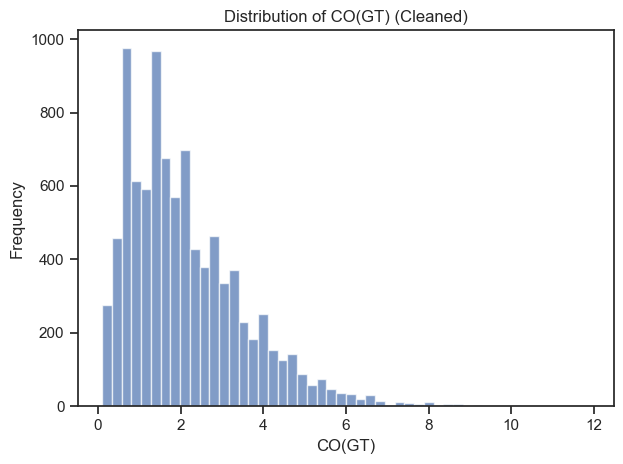

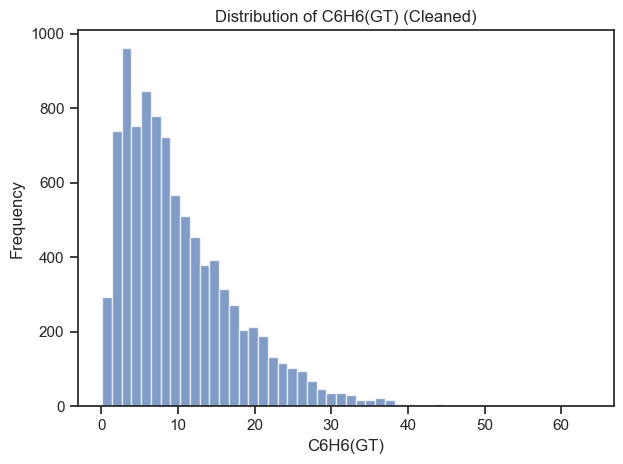

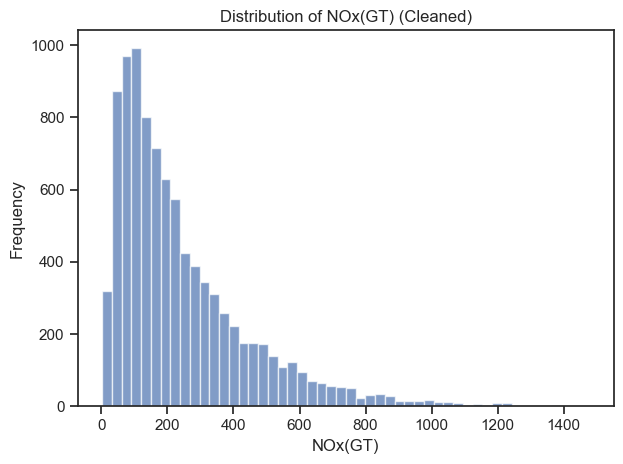

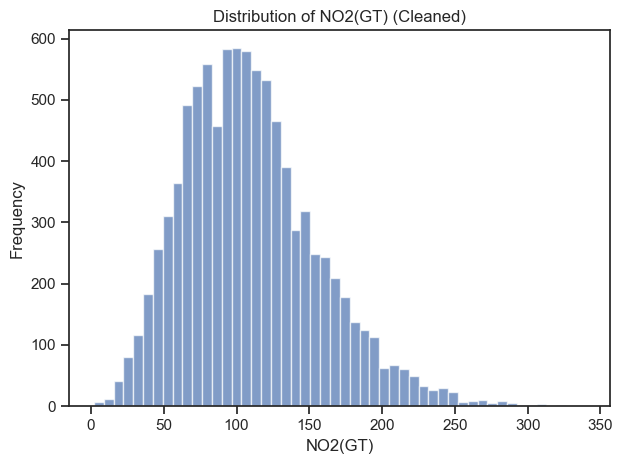

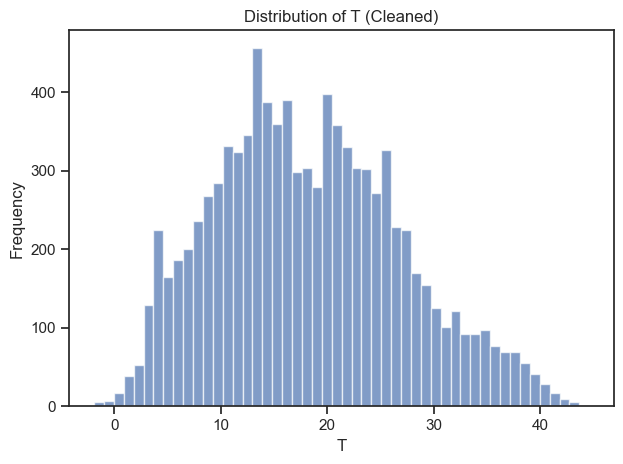

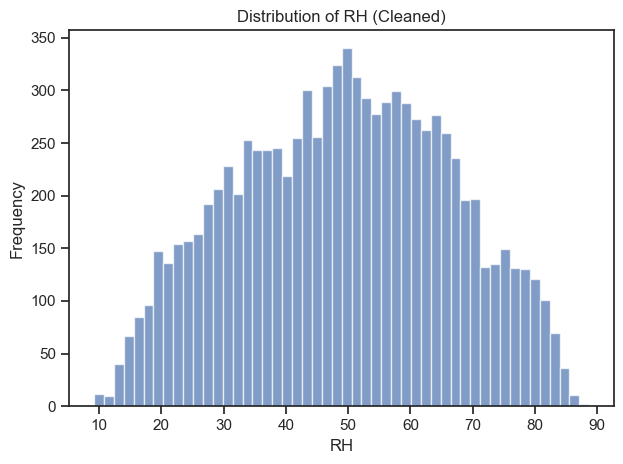

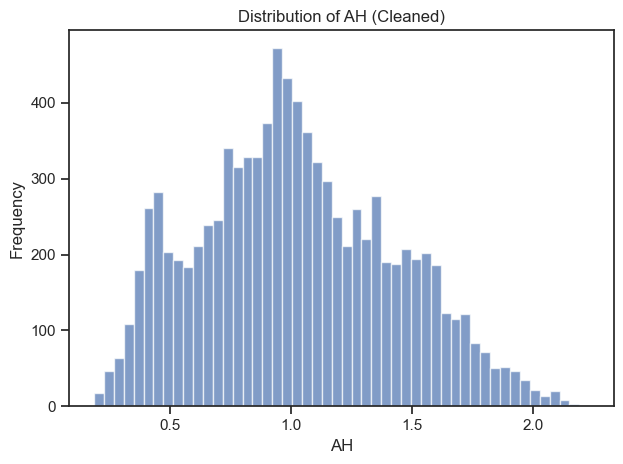

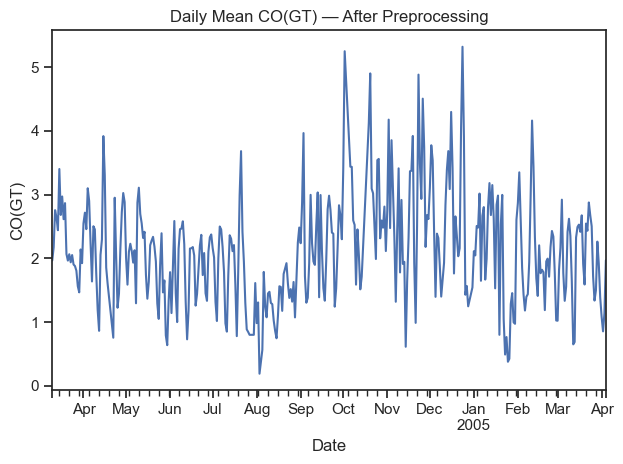

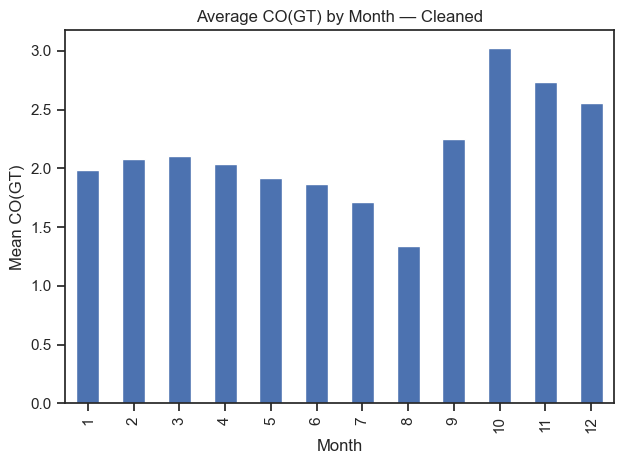

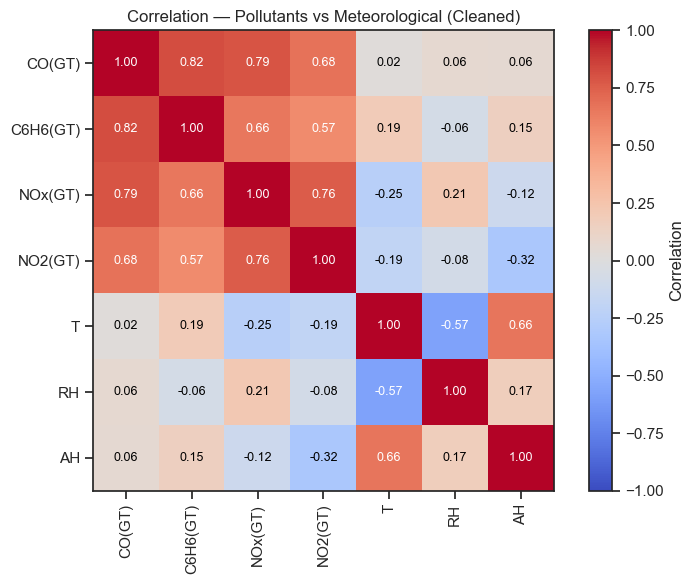

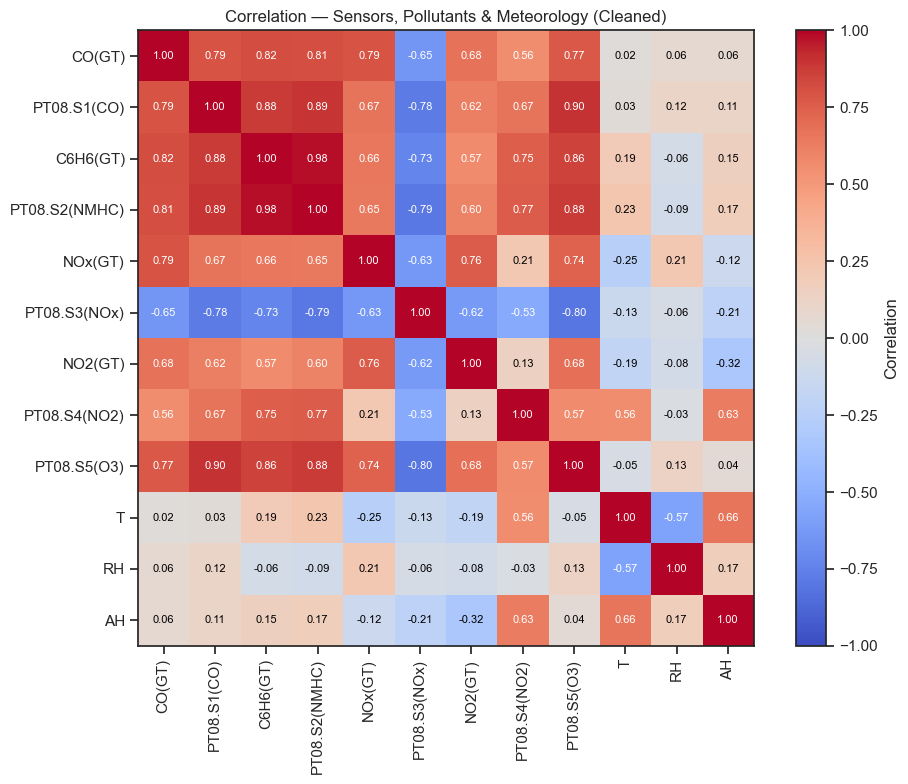

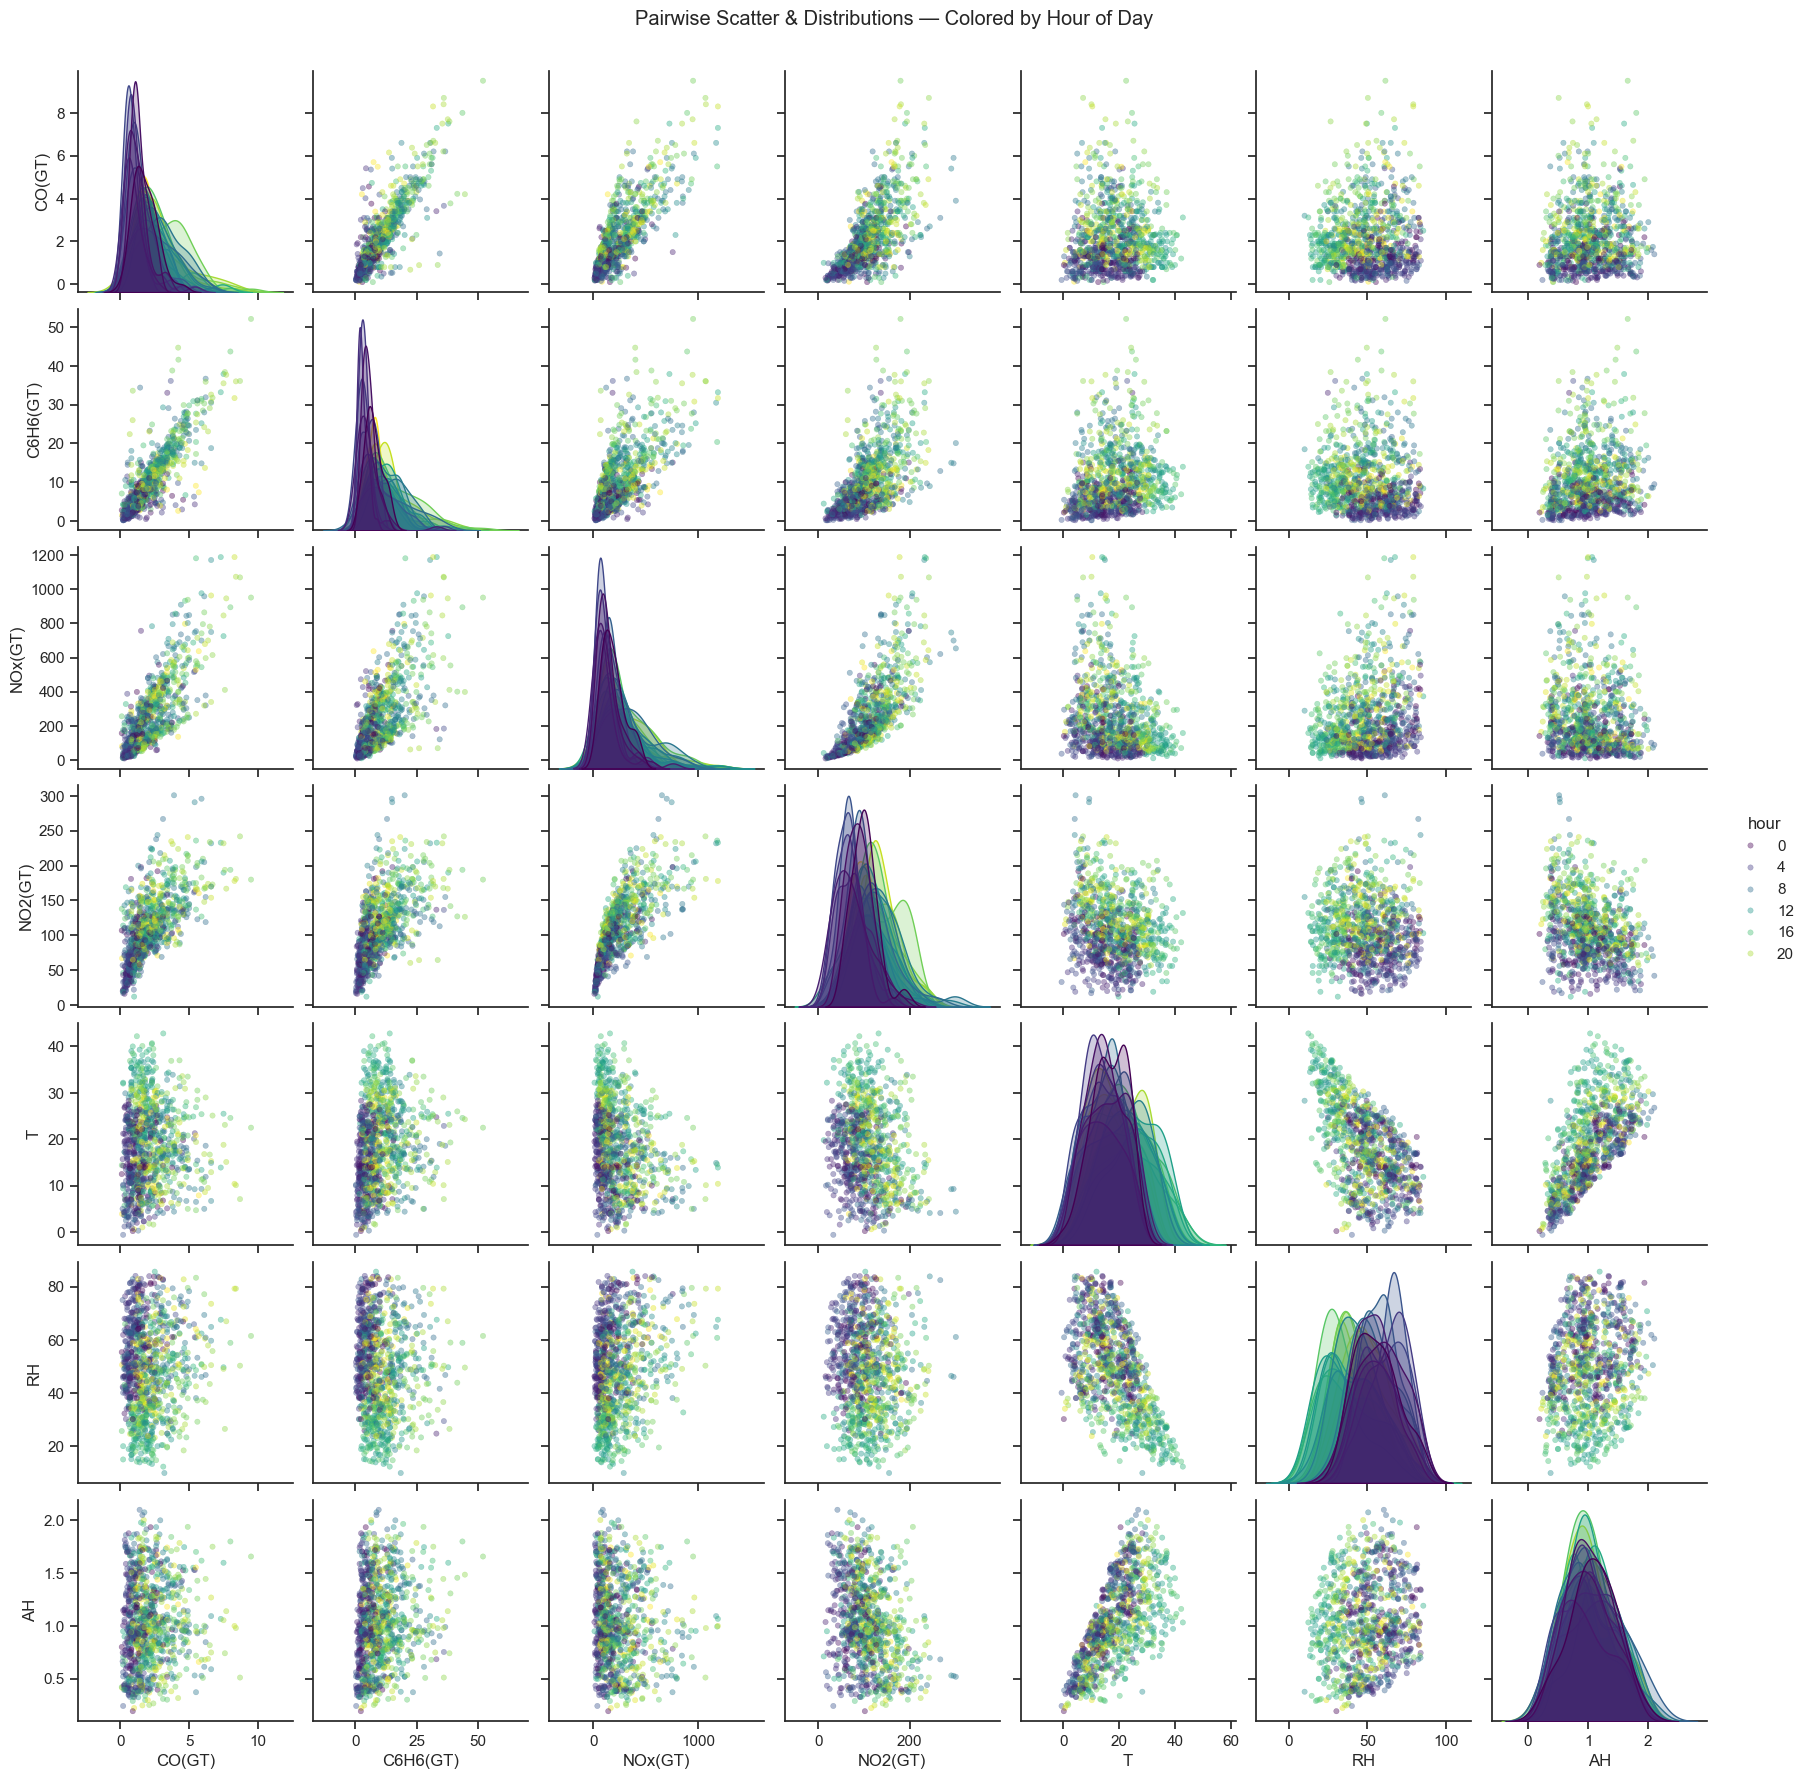

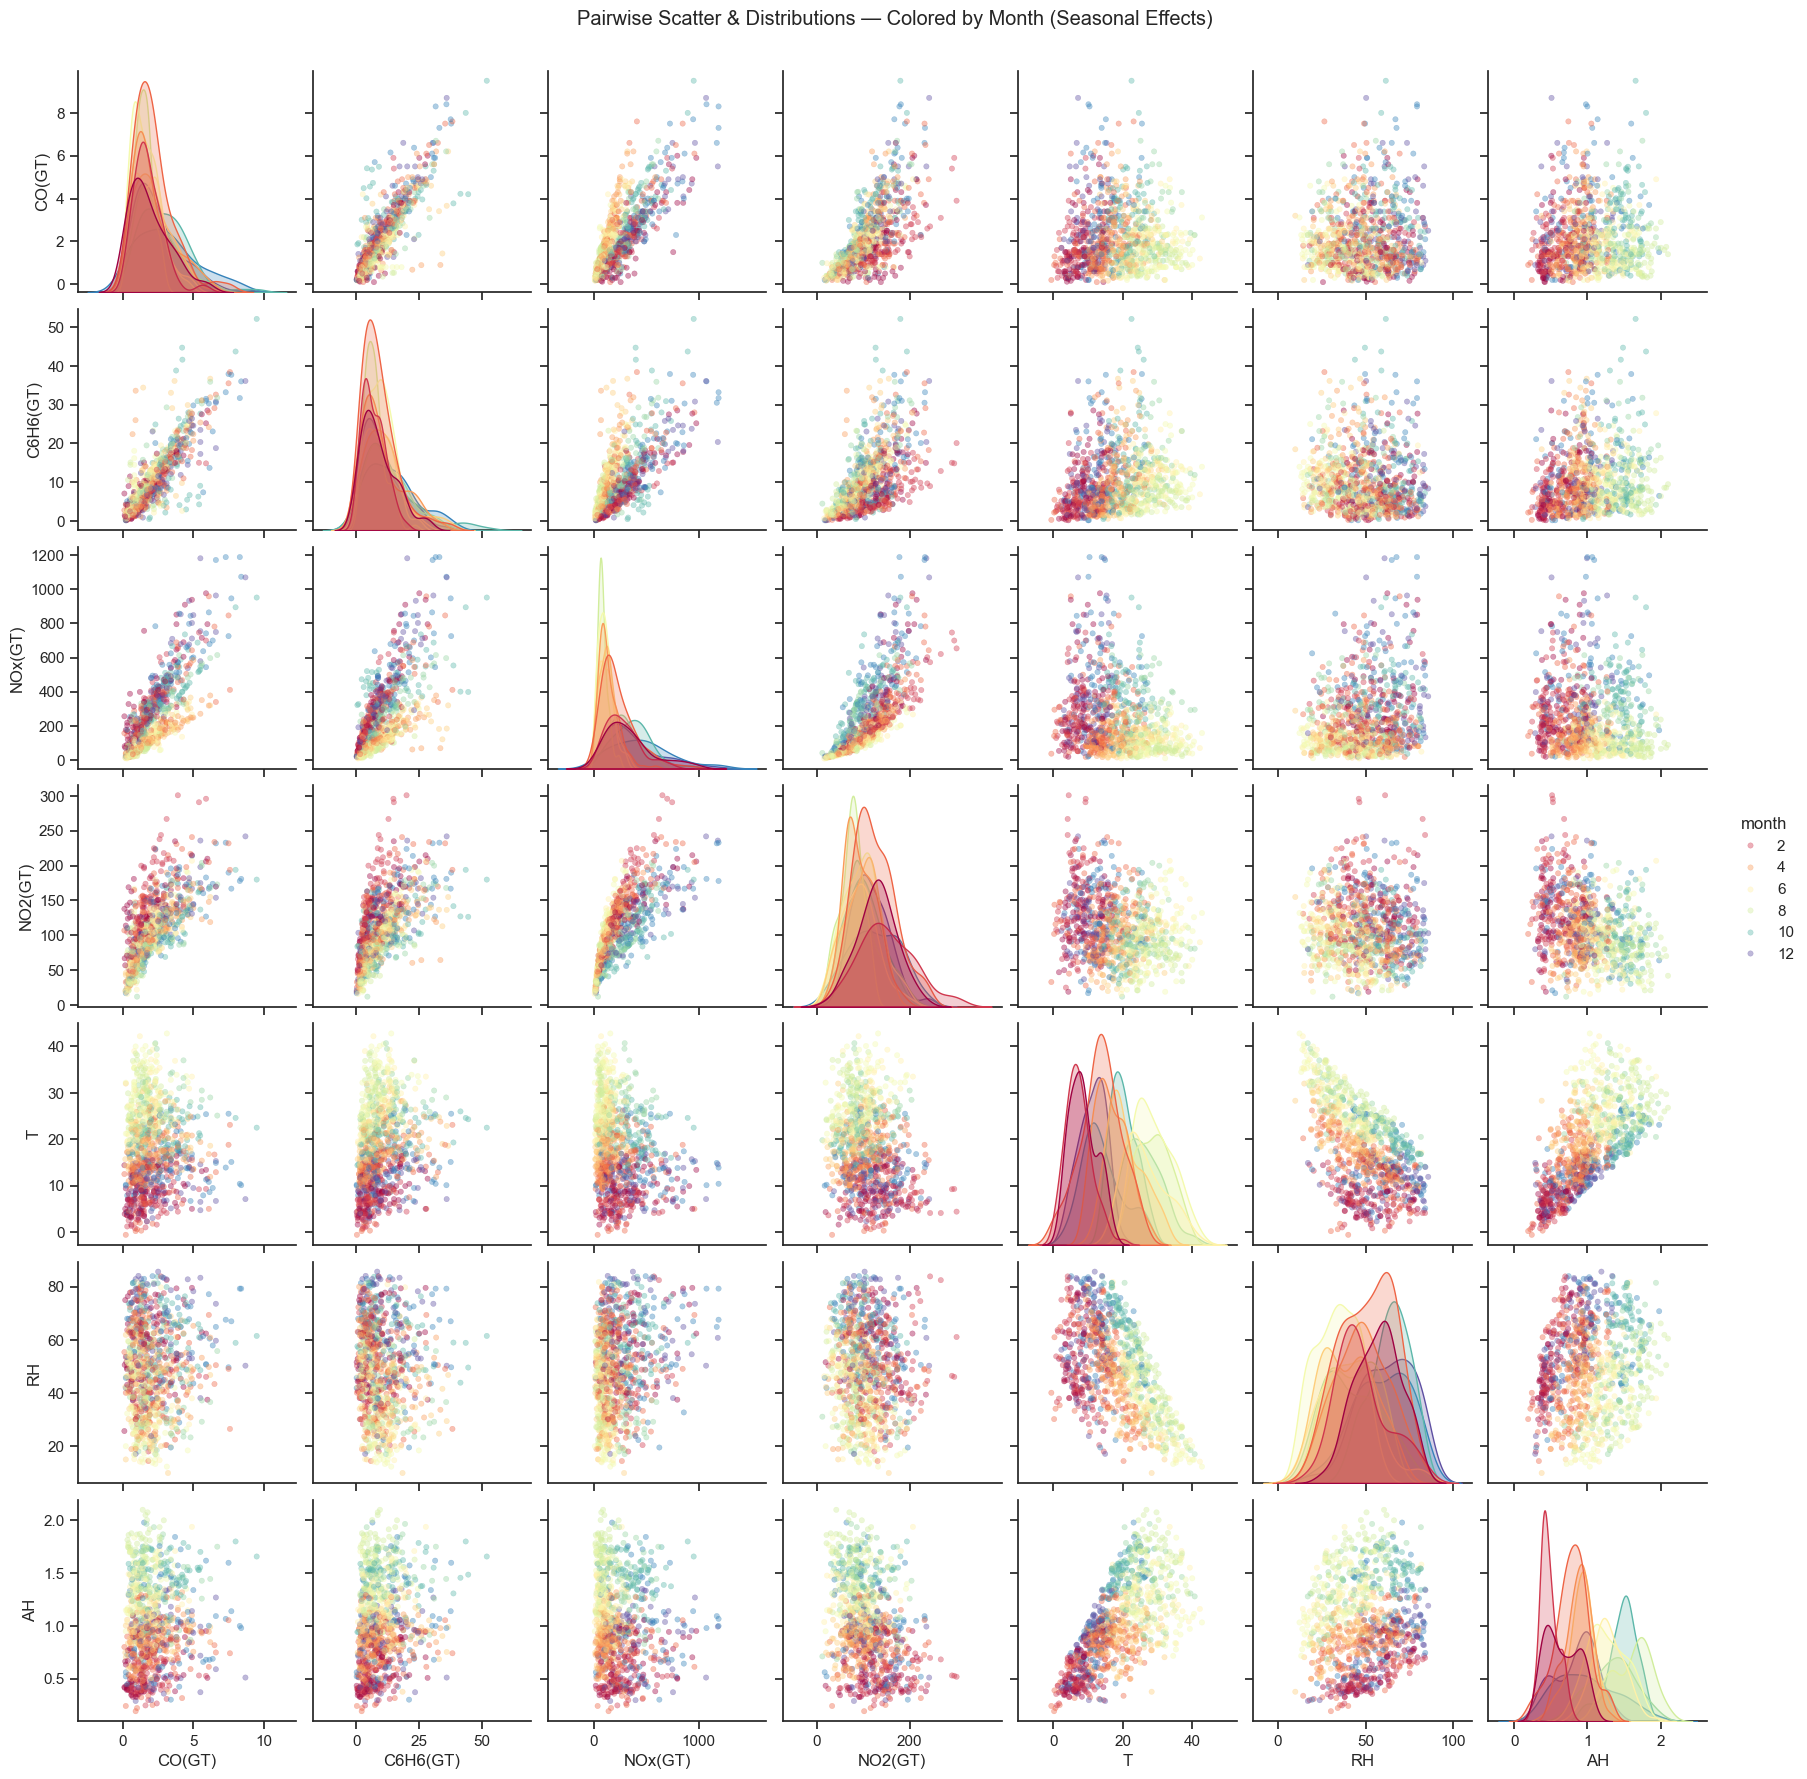


EDA-after-preprocessing completed.


In [14]:
# =====================================================
# COMP9417 Air Quality Project
# STEP 3 — EDA AFTER PREPROCESSING
# =====================================================
# Goals:
#   1. Confirm cleaning worked (no sentinel -200, few NaNs)
#   2. Re-examine variable distributions & correlations
#   3. Validate temporal continuity and seasonal behavior
# =====================================================
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------- 1. Load cleaned dataset ----------
df = pd.read_csv("AirQuality_clean.csv", parse_dates=["timestamp"])
print("Cleaned shape:", df.shape)
print("Columns:", df.columns.tolist())

# ---------- 2. Check for any remaining NaNs ----------
na_summary = df.isna().sum()
print("\nRemaining NaN counts (top 10):")
print(na_summary.sort_values(ascending=False).head(10))

# ---------- 3. Confirm no more -200 sentinels ----------
sentinel_check = (df == -200).sum().sum()
print(f"\nSentinel (-200) values remaining: {sentinel_check}")

# ---------- 4. Time coverage check ----------
print("\nTimestamp coverage:")
print("From:", df["timestamp"].min(), "→ To:", df["timestamp"].max())

# ---------- 5. Distribution plots for key variables ----------
pollutants = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
met_vars   = ["T", "RH", "AH"]

for col in pollutants + met_vars:
    if col in df.columns:
        plt.figure()
        df[col].plot(kind="hist", bins=50, alpha=0.7)
        plt.title(f"Distribution of {col} (Cleaned)")
        plt.xlabel(col); plt.ylabel("Frequency")
        plt.tight_layout()
        plt.show()

# ---------- 6. Daily & monthly trends for CO(GT) ----------
if "CO(GT)" in df.columns:
    daily_co = df.set_index("timestamp")["CO(GT)"].resample("D").mean()
    plt.figure()
    daily_co.plot(title="Daily Mean CO(GT) — After Preprocessing")
    plt.xlabel("Date"); plt.ylabel("CO(GT)")
    plt.tight_layout(); plt.show()

    monthly_co = df.groupby(df["timestamp"].dt.month)["CO(GT)"].mean()
    plt.figure()
    monthly_co.plot(kind="bar", title="Average CO(GT) by Month — Cleaned")
    plt.xlabel("Month"); plt.ylabel("Mean CO(GT)")
    plt.tight_layout(); plt.show()

# ---------- 7A. Correlation — GT pollutants + meteorological ----------
chem_cols = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]
met_cols  = ["T", "RH", "AH"]
corr_cols = [c for c in chem_cols + met_cols if c in df.columns]
corr = df[corr_cols].corr()

plt.figure(figsize=(8,6))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.iloc[i,j]
        plt.text(j,i,f"{v:.2f}", ha="center", va="center",
                 color="black" if abs(v)<0.5 else "white", fontsize=9)
plt.xticks(np.arange(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(np.arange(len(corr_cols)), corr_cols)
plt.title("Correlation — Pollutants vs Meteorological (Cleaned)")
plt.colorbar(im, label="Correlation")
plt.tight_layout()
plt.show()

# ---------- 7B. Correlation — GT + PT08 sensors + meteorological ----------
cand = [c for c in df.columns if "(GT)" in c or c.startswith("PT08.") or c in {"T","RH","AH"}]
df_num = df[cand].apply(pd.to_numeric, errors="coerce")
keep = [c for c in df_num.columns if df_num[c].notna().any()]
corr_full = df_num[keep].corr()

plt.figure(figsize=(10,8))
im = plt.imshow(corr_full, cmap="coolwarm", vmin=-1, vmax=1)
for i in range(len(keep)):
    for j in range(len(keep)):
        val = corr_full.iloc[i,j]
        plt.text(j,i,f"{val:.2f}",
                 ha="center",va="center",
                 color="black" if abs(val)<0.5 else "white",
                 fontsize=8)
plt.xticks(np.arange(len(keep)), keep, rotation=90)
plt.yticks(np.arange(len(keep)), keep)
plt.title("Correlation — Sensors, Pollutants & Meteorology (Cleaned)")
plt.colorbar(im, label="Correlation")
plt.tight_layout(); plt.show()

# ---------- 8. Scatter plots — all distributions with time-based color coding ----------
import seaborn as sns

# Variables of interest: pollutants + meteorology
scatter_vars = [
    "CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)",
    "T", "RH", "AH"
]
# Keep only those columns that exist
scatter_vars = [c for c in scatter_vars if c in df.columns]

# Create time features if not already there
if "hour" not in df.columns:
    df["hour"] = df["timestamp"].dt.hour
if "month" not in df.columns:
    df["month"] = df["timestamp"].dt.month

# Random subsample (makes pairplot faster)
sample_df = df[scatter_vars + ["hour", "month"]].sample(n=min(1000, len(df)), random_state=42)

sns.set(style="ticks", font_scale=1.0)

# ---- 8A. Pairplot color-coded by hour of day ----
g1 = sns.pairplot(
    sample_df,
    vars=scatter_vars,
    hue="hour",
    palette="viridis",
    diag_kind="kde",
    plot_kws={"alpha": 0.4, "s": 15, "edgecolor": None}
)
g1.fig.suptitle("Pairwise Scatter & Distributions — Colored by Hour of Day", y=1.02)
plt.show()

# ---- 8B. Pairplot color-coded by month ----
g2 = sns.pairplot(
    sample_df,
    vars=scatter_vars,
    hue="month",
    palette="Spectral",
    diag_kind="kde",
    plot_kws={"alpha": 0.4, "s": 15, "edgecolor": None}
)
g2.fig.suptitle("Pairwise Scatter & Distributions — Colored by Month (Seasonal Effects)", y=1.02)
plt.show()

print("\nEDA-after-preprocessing completed.")


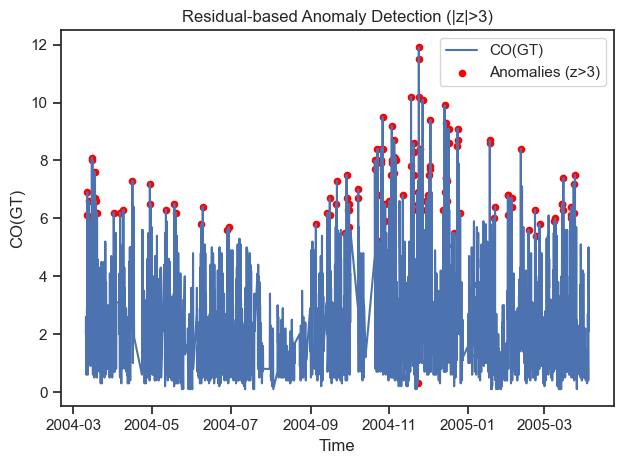

Residual-based anomalies detected: 126


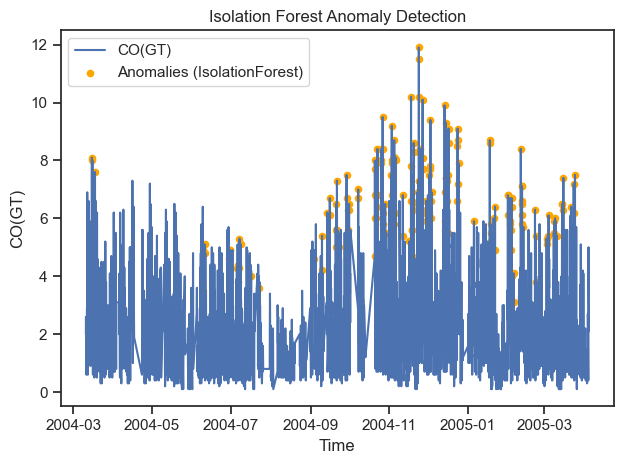

Isolation Forest anomalies detected: 188


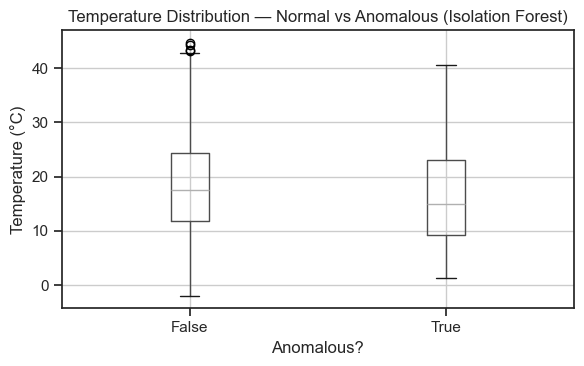

Proportion of Isolation Forest anomalies on weekends: 0.02


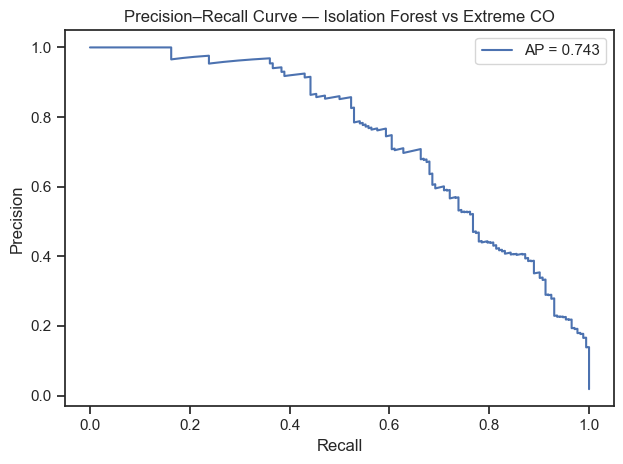

Average Precision Score (Isolation Forest vs Extreme CO): 0.743

Saved combined anomalies → AirQuality_anomalies.csv


In [15]:
# =====================================================
# COMP9417 Air Quality Project
# STEP 4 — ANOMALY AND EVENT DETECTION
# =====================================================
# Detects unexpected pollution spikes or faulty readings
# using residual- and model-based methods.
# =====================================================
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_recall_curve, average_precision_score

# ---------- 1. Load cleaned data ----------
df = pd.read_csv("AirQuality_clean.csv", parse_dates=["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

# ---------- 2. Choose pollutant to monitor ----------
target = "CO(GT)"  # you can change this to NOx(GT), NO2(GT), etc.
y = df[target].copy()

# ---------- 3. Residual-based anomaly detection ----------
window = 24  # 24-hour rolling mean
rolling_mean = y.rolling(window=window, center=True).mean()
residual = y - rolling_mean
zscore = (residual - residual.mean()) / residual.std()

# mark anomalies with z-score > 3 σ
threshold = 3
anomalies_resid = df.loc[zscore.abs() > threshold, ["timestamp", target]].copy()
anomalies_resid["method"] = "zscore>3"

plt.figure()
plt.plot(df["timestamp"], y, label="CO(GT)")
plt.scatter(anomalies_resid["timestamp"], anomalies_resid[target],
            color="red", s=20, label="Anomalies (z>3)")
plt.title("Residual-based Anomaly Detection (|z|>3)")
plt.xlabel("Time"); plt.ylabel("CO(GT)")
plt.legend(); plt.tight_layout(); plt.show()

print(f"Residual-based anomalies detected: {len(anomalies_resid)}")

# ---------- 4. Unsupervised anomaly detection (Isolation Forest) ----------
features = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)", "T", "RH", "AH"]
features = [f for f in features if f in df.columns]

X = df[features].ffill().bfill()

iso = IsolationForest(contamination=0.02, random_state=42)
df["anomaly_iforest"] = iso.fit_predict(X)  # -1 = anomaly, 1 = normal

anomalies_iforest = df[df["anomaly_iforest"] == -1][["timestamp", target]]
anomalies_iforest["method"] = "IsolationForest"

plt.figure()
plt.plot(df["timestamp"], y, label="CO(GT)")
plt.scatter(anomalies_iforest["timestamp"], anomalies_iforest[target],
            color="orange", s=20, label="Anomalies (IsolationForest)")
plt.title("Isolation Forest Anomaly Detection")
plt.xlabel("Time"); plt.ylabel("CO(GT)")
plt.legend(); plt.tight_layout(); plt.show()

print(f"Isolation Forest anomalies detected: {len(anomalies_iforest)}")

# ---------- 5. Compare anomalies with meteorological & calendar factors ----------
# Preconditions (fail fast if something's missing)
assert "timestamp" in df.columns, "Parse timestamp first"
assert "T" in df.columns, "Column 'T' missing"
assert "anomaly_iforest" in df.columns, "Run Isolation Forest step first"

# Time features (ok if already present)
df["hour"] = df["timestamp"].dt.hour
df["weekday"] = df["timestamp"].dt.dayofweek  # 0=Mon
df["month"] = df["timestamp"].dt.month
df["is_weekend"] = df["weekday"].isin([5, 6])

# Anomaly flags (ok if already present)
df["is_anomaly_resid"]   = zscore.abs() > threshold
df["is_anomaly_iforest"] = df["anomaly_iforest"] == -1

subset = df[["T", "is_anomaly_iforest"]].dropna()

fig, ax = plt.subplots(figsize=(6, 4))
subset.boxplot(column="T", by="is_anomaly_iforest", ax=ax)
ax.set_title("Temperature Distribution — Normal vs Anomalous (Isolation Forest)")
fig.suptitle("")  # hide pandas' automatic super title
ax.set_xlabel("Anomalous?")
ax.set_ylabel("Temperature (°C)")
fig.tight_layout()
plt.show()


# Weekend proportion of anomalies
weekend_ratio = df.loc[df["is_anomaly_iforest"], "is_weekend"].mean()
print(f"Proportion of Isolation Forest anomalies on weekends: {weekend_ratio:.2f}")

# ---------- 6. Evaluate precision–recall trade-off (synthetic check) ----------
# Create pseudo ground truth: extreme top 2 % CO as 'true anomalies'
threshold_true = y.quantile(0.98)
true_labels = (y > threshold_true).astype(int)
scores = -iso.decision_function(X)  # higher = more anomalous
precision, recall, _ = precision_recall_curve(true_labels, scores)
ap = average_precision_score(true_labels, scores)

plt.figure()
plt.plot(recall, precision, label=f"AP = {ap:.3f}")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision–Recall Curve — Isolation Forest vs Extreme CO")
plt.legend(); plt.tight_layout(); plt.show()

print(f"Average Precision Score (Isolation Forest vs Extreme CO): {ap:.3f}")

# ---------- 7. Save anomaly records ----------
anomalies = pd.concat([anomalies_resid, anomalies_iforest]).sort_values("timestamp")
anomalies.to_csv("AirQuality_anomalies.csv", index=False)
print("\nSaved combined anomalies → AirQuality_anomalies.csv")



Weekend proportion among anomalies: 0.04


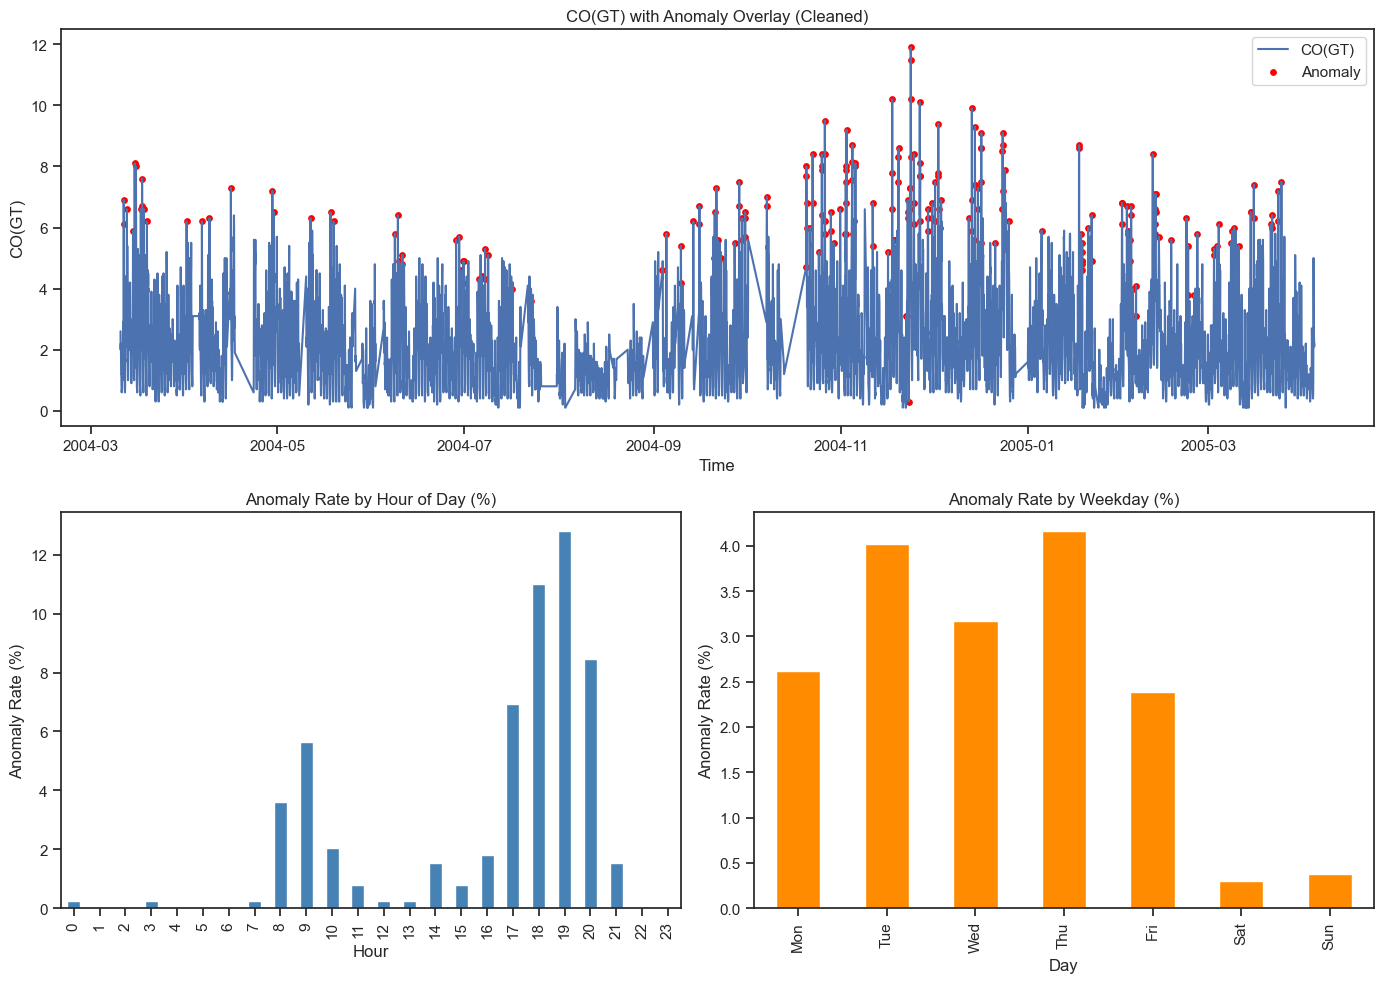

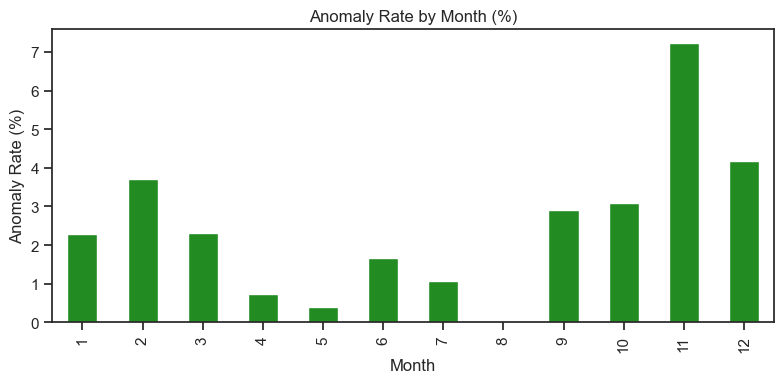

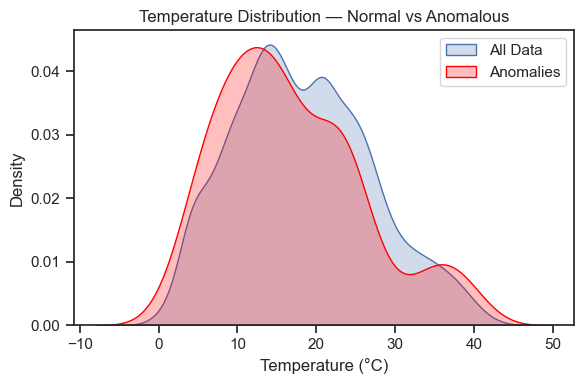

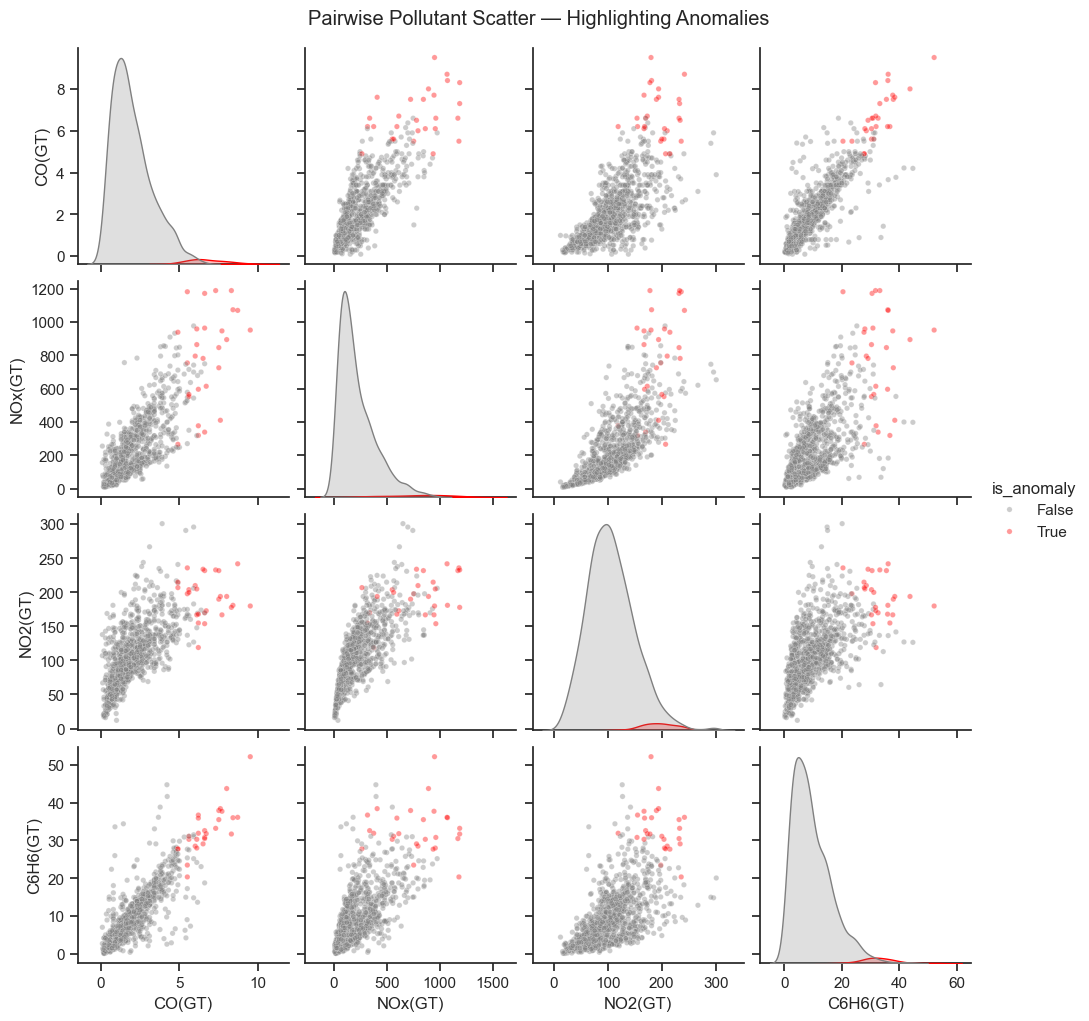

In [16]:
# =====================================================
# COMP9417 Air Quality Project
# STEP 4B — ANOMALY DASHBOARD & INTERPRETATION
# =====================================================
# Visual summary of anomaly patterns across time and conditions
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec

# ---------- 1. Load anomalies and base data ----------
df = pd.read_csv("AirQuality_clean.csv", parse_dates=["timestamp"])
anom = pd.read_csv("AirQuality_anomalies.csv", parse_dates=["timestamp"])

df["hour"] = df["timestamp"].dt.hour
df["weekday"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.month
df["is_weekend"] = df["weekday"].isin([5,6])

# Merge anomaly flags
df["is_anomaly"] = df["timestamp"].isin(anom["timestamp"])

# ---------- 2. Count anomalies by time dimensions ----------
hourly_anoms = df.groupby("hour")["is_anomaly"].mean() * 100
weekday_anoms = df.groupby("weekday")["is_anomaly"].mean() * 100
monthly_anoms = df.groupby("month")["is_anomaly"].mean() * 100

# ---------- 3. Overall proportions ----------
weekend_prop = df.loc[df["is_anomaly"], "is_weekend"].mean()
print(f"Weekend proportion among anomalies: {weekend_prop:.2f}")

# ---------- 4. Dashboard layout ----------
plt.figure(figsize=(14, 10))
gs = GridSpec(2, 2)

# ---- (a) Time-series overview
ax0 = plt.subplot(gs[0, :])
plt.plot(df["timestamp"], df["CO(GT)"], label="CO(GT)")
plt.scatter(df.loc[df["is_anomaly"], "timestamp"],
            df.loc[df["is_anomaly"], "CO(GT)"],
            color="red", s=15, label="Anomaly")
plt.title("CO(GT) with Anomaly Overlay (Cleaned)")
plt.xlabel("Time"); plt.ylabel("CO(GT)")
plt.legend(); plt.tight_layout(pad=2.0)

# ---- (b) Hour-of-day
ax1 = plt.subplot(gs[1, 0])
hourly_anoms.plot(kind="bar", color="steelblue")
plt.title("Anomaly Rate by Hour of Day (%)")
plt.xlabel("Hour"); plt.ylabel("Anomaly Rate (%)")

# ---- (c) Weekday pattern
ax2 = plt.subplot(gs[1, 1])
days = ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"]
weekday_anoms.index = days
weekday_anoms.plot(kind="bar", color="darkorange")
plt.title("Anomaly Rate by Weekday (%)")
plt.xlabel("Day"); plt.ylabel("Anomaly Rate (%)")

plt.tight_layout()
plt.show()

# ---------- 5. Monthly distribution ----------
plt.figure(figsize=(8,4))
monthly_anoms.plot(kind="bar", color="forestgreen")
plt.title("Anomaly Rate by Month (%)")
plt.xlabel("Month"); plt.ylabel("Anomaly Rate (%)")
plt.tight_layout(); plt.show()

# ---------- 6. Temperature vs anomalies ----------
plt.figure(figsize=(6,4))
sns.kdeplot(df["T"], fill=True, label="All Data")
sns.kdeplot(df.loc[df["is_anomaly"], "T"], fill=True, label="Anomalies", color="red")
plt.title("Temperature Distribution — Normal vs Anomalous")
plt.xlabel("Temperature (°C)"); plt.legend(); plt.tight_layout(); plt.show()

# ---------- 7. Pairwise pollutant comparison for anomalies ----------
polls = ["CO(GT)", "NOx(GT)", "NO2(GT)", "C6H6(GT)"]
polls = [p for p in polls if p in df.columns]
sns.pairplot(df.sample(n=min(1000,len(df)), random_state=42),
             vars=polls, hue="is_anomaly",
             palette={False:"gray", True:"red"},
             diag_kind="kde", plot_kws={"alpha":0.4, "s":15})
plt.suptitle("Pairwise Pollutant Scatter — Highlighting Anomalies", y=1.02)
plt.show()